# 04 – Continuous Frequency Sweep (Rolling Monitor)

This notebook starts the rolling monitor for unattended continuous measurement
and provides offline post-analysis of completed sessions.
Acquisition cells (2–3) require hardware; analysis cells (from cell 6 onward)
run offline using stored `SESSION_ID`.

**Background:**
Plant acoustic emission (AE) in the ultrasonic range originates primarily from
xylem cavitation and hydraulic stress (Zweifel & Zeugin, 2008; De Roo et al., 2016;
Khait et al., 2023). Time–frequency tracking over multiple days allows separation
of plant-coupled signals from structural artefacts (Oletic et al., 2020).

## Architecture

```
ContinuousFrequencyMonitor
├── RamFrameRing          – RAM ring of all frames (dynamic budget)
├── PeakTracker           – per-channel peak persistence
├── CandidateTracker      – fine-frequency tracking at 3800 Hz and 6750 Hz
│   (parabolic sub-bin interpolation, Welch coherence, SNR, artefact proximity)
└── EventLog              – JSONL event stream
```

**Output** (per session): `data/reports/notebooks/04_continuous_frequency_sweep/<session_id>/`
```
frames.jsonl        per-frame features (band energy, peaks, candidate_analysis, temperature)
events.jsonl        detected events (rolling + connection events)
heartbeat.json      updated atomically after each frame; used by measurement.py status
```

**Active sensor setup (from 2026-06-30):**

| Channel | Signal | Source / Position | Role |
|---------|--------|-------------------|------|
| CH1 | amplifier + 820 kΩ + piezo | piezo probe | acoustic sensor |
| CH2 | **DISABLED** | — | Hardware defect / spare only if explicitly re-enabled |
| CH3 | amplifier + 820 kΩ + piezo + metal rod | metal-rod probe A | acoustic sensor / rod-coupled response |
| CH4 | amplifier + 820 kΩ + piezo + metal rod | metal-rod probe B | acoustic sensor / rod-coupled response |

**Current interpretation:**
- CH1 is an amplified piezo sensor, not a Pico marker, not an EM reference.
- CH3 and CH4 are amplified piezo sensors coupled through metal rods.
- Runs started before this correction may have valid raw CH3/CH4 data but stale labels and CH1 scaling/interpretation.


## Acquisition


In [ ]:
import sys, time, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

from plant_ae.watering import CHARACTERIZATION_ROOT, HOMEASSISTANT_ENABLED_ENV, homeassistant_enabled
if str(CHARACTERIZATION_ROOT) not in sys.path:
    sys.path.insert(0, str(CHARACTERIZATION_ROOT))

from plant_ae.deep_acquisition import (
    configure_deep_memory_scope,
    acquire_deep_memory_frame,
    DEFAULT_SAMPLE_RATE_HZ,
    DEFAULT_MEMORY_DEPTH,
)
from plant_ae.rolling import (
    ContinuousFrequencyMonitor,
    extract_frame_features,
    MAINS_HARMONIC_BANDS_HZ,
    summarize_monitor_sessions,
)
from plant_ae.watering import CHANNELS, CONFIG_PATH  # CH1/CH3/CH4 (CH2 defekt)
from scope.config import load_config
from scope.instrument import InstrumentConnection
from IPython.display import clear_output, display

DURATION_HOURS = None          # None = endlos bis Ctrl+C
DASHBOARD_EVERY = 5            # Dashboard alle N Frames aktualisieren
EVENTS_FILE = CHARACTERIZATION_ROOT / "data" / "rolling_events_manual.jsonl"
# Home Assistant temperature sensor (optional, for correlation analysis)
import importlib.util, sys as _sys
TEMPERATURE_ENTITY = "sensor.satellite1_c412d0_temperature"
_ha_client = None
try:
    if not homeassistant_enabled(default=False):
        raise RuntimeError(f"{HOMEASSISTANT_ENABLED_ENV} is not enabled")
    _actuator_path = CHARACTERIZATION_ROOT / "actuator" / "giessen_pflanze1.py"
    _spec = importlib.util.spec_from_file_location("plant1_actuator", _actuator_path)
    if _spec is None or _spec.loader is None:
        raise RuntimeError(f"cannot load actuator module: {_actuator_path}")
    _act_mod = importlib.util.module_from_spec(_spec)
    _spec.loader.exec_module(_act_mod)
    _sync_dir = _act_mod.DEFAULT_SYNC_DIR
    _sync_mod = _act_mod.load_homeassistant_sync(_sync_dir)
    _ha_url, _ha_token = _act_mod.load_connection_settings(_sync_mod, _sync_dir, ha_url=None, token=None)
    _ha_client = _sync_mod.HomeAssistantRestClient(_ha_url, _ha_token, timeout=5.0)
except Exception as exc:
    print(f"Home Assistant temperature disabled: {exc}")

def _poll_temperature() -> float | None:
    if _ha_client is None:
        return None
    try:
        result = _ha_client.get(f"/api/states/{TEMPERATURE_ENTITY}")
        return float(result["state"])
    except Exception:
        return None


In [ ]:
monitor = ContinuousFrequencyMonitor(
    persist_events=True,
    persist_frames=True,
    save_event_raw=False,
    timezone_name="Europe/Berlin",
    day_start_hour=6,
    night_start_hour=22,
    temperature_poller=_poll_temperature,
)
monitor.output_dir.mkdir(parents=True, exist_ok=True)

config = load_config(CONFIG_PATH)
started = time.monotonic()
sequence = 0

# Reconnect parameters: after MAX_CONSEC_ERRORS consecutive frame errors,
# the connection is closed and re-opened after RECONNECT_WAIT_S seconds.
# monitor state (ring, events, tracks) is preserved across reconnects.
MAX_CONSEC_ERRORS = 5
RECONNECT_WAIT_S  = 30


def _time_ok() -> bool:
    return DURATION_HOURS is None or time.monotonic() - started < DURATION_HOURS * 3600


def _log_connection_event(kind: str, **extra) -> None:
    """Write a connection event directly to the session events file."""
    import json as _j
    from datetime import datetime as _dt, timezone as _tz
    event = {
        "timestamp_utc": _dt.now(_tz.utc).isoformat(),
        "type": kind,
        "sequence_at_event": sequence,
        **extra,
    }
    with (monitor.output_dir / "events.jsonl").open("a") as _fh:
        _fh.write(_j.dumps(event) + "\n")


try:
    while _time_ok():
        # --- Outer loop: establish / restore connection ---
        try:
            with InstrumentConnection(config) as conn:
                profile = configure_deep_memory_scope(conn)
                print(f"[{time.strftime('%H:%M:%S')}] Connected — "
                      f"{profile['profile']}, "
                      f"{profile['sample_rate_hz']/1e3:.0f} kSa/s, "
                      f"{profile['memory_depth']:,} points, "
                      f"Δf={profile['frequency_resolution_hz']:.2f} Hz")
                consec_errors = 0

                # --- Inner loop: frame acquisition ---
                while _time_ok():
                    try:
                        captures = acquire_deep_memory_frame(
                            conn, config, sequence=sequence,
                            sample_rate_hz=DEFAULT_SAMPLE_RATE_HZ,
                            memory_depth=DEFAULT_MEMORY_DEPTH,
                        )
                        frame = extract_frame_features(
                            sequence, captures,
                            ignore_frequency_bands_hz=MAINS_HARMONIC_BANDS_HZ,
                        )
                        events = monitor.process_frame(frame)
                        consec_errors = 0
                        if events:
                            print(f"[{time.strftime('%H:%M:%S')}] "
                                  f"seq {sequence:4d}: {len(events)} event(s)")
                            for e in events:
                                print(f"  [{e['type']}]",
                                      {k: v for k, v in e.items() if k != "type"})
                        if sequence % DASHBOARD_EVERY == 0:
                            clear_output(wait=True)
                            fig = monitor.plot_dashboard(frame)
                            display(fig)
                            plt.close(fig)
                        sequence += 1

                    except KeyboardInterrupt:
                        raise
                    except Exception as exc:
                        consec_errors += 1
                        print(f"[{time.strftime('%H:%M:%S')}] seq {sequence}: "
                              f"error ({consec_errors}/{MAX_CONSEC_ERRORS}) — {exc}")
                        if consec_errors >= MAX_CONSEC_ERRORS:
                            print(f"[{time.strftime('%H:%M:%S')}] "
                                  f"Too many errors — closing connection for reconnect.")
                            _log_connection_event(
                                "connection_lost",
                                consecutive_errors=consec_errors,
                                last_error=str(exc),
                            )
                            break  # exits inner loop; with-block closes conn
                        time.sleep(2.0)

        except KeyboardInterrupt:
            raise
        except Exception as exc:
            # connection setup failed
            print(f"[{time.strftime('%H:%M:%S')}] Connection failed: {exc}")
            _log_connection_event("connection_error", error=str(exc))

        # --- Wait before reconnect ---
        if _time_ok():
            print(f"[{time.strftime('%H:%M:%S')}] Reconnect in {RECONNECT_WAIT_S}s ... "
                  f"(seq={sequence})")
            time.sleep(RECONNECT_WAIT_S)

except KeyboardInterrupt:
    print(f"\n[{time.strftime('%H:%M:%S')}] Stopped at seq {sequence}")
finally:
    monitor.finish("finished")
    print("Status:", monitor.status())

## Event Summary (post-run)

Loads saved events from the current session and prints a summary.


In [ ]:
events_path = monitor.output_dir / "events.jsonl"
events = []
if events_path.exists():
    with events_path.open() as f:
        events = [json.loads(line) for line in f if line.strip()]

by_type = {}
for e in events:
    by_type.setdefault(e["type"], []).append(e)

print(f"Total: {len(events)} events")
for t, lst in sorted(by_type.items()):
    print(f"  {t}: {len(lst)}x")

trend_summary = summarize_monitor_sessions()
print(f"\nLong-term trend sessions: {trend_summary['sessions']}")
print("Frames by phase:", trend_summary["phase_frames"])
print("Top trends:")
for trend in trend_summary["top_trends"][:10]:
    print(
        f"  {trend['kind']} CH{trend['channel']} {trend['label']}: "
        f"{trend['total_change']:+.2f} {trend['unit']} over "
        f"{trend['hourly_points']} hourly points, R²={trend['r_squared']:.2f}"
    )

---
## Offline Post-Analysis

`SESSION_ID = None` selects the latest session automatically.
All cells from here run without scope hardware.


In [1]:
import sys, json
from pathlib import Path
from datetime import datetime
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
from scipy.signal import medfilt

%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

CHARROOT = Path("/media/christoph/some_space/Nextcloud/hs-augsburg"
                "/Semester_6/Projekt_I1/projekt_i1/src/characterization")
if str(CHARROOT) not in sys.path:
    sys.path.insert(0, str(CHARROOT))

from plant_ae.rolling import REPORT_ROOT, summarize_monitor_sessions

plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.3})

# Latest session selected automatically; override: SESSION_ID = "20260623_004454"
SESSION_ID = None
if SESSION_ID is None:
    sessions = sorted(REPORT_ROOT.glob("20*/manifest.json"))
    assert sessions, "No session found in " + str(REPORT_ROOT)
    SESSION_ID = sessions[-1].parent.name
SESSION_DIR = REPORT_ROOT / SESSION_ID

manifest = json.loads((SESSION_DIR / "manifest.json").read_text())
print(f"Session : {SESSION_ID}")
print(f"Start   : {manifest['started_utc'][:19]} UTC")
print(f"End     : {manifest['finished_utc'][:19]} UTC")
print(f"Frames  : {manifest['frames_processed']}")
print(f"Events  : {manifest['monitor_status']['events']}")
print(f"RAM     : {manifest['monitor_status']['ring_usage_gib']:.1f} GiB")

Session : 20260623_004454
Start   : 2026-06-22T22:44:54 UTC
Ende    : 2026-06-23T08:37:40 UTC
Frames  : 907
Events  : 246
RAM     : 5.1 GiB


In [2]:
frames = [json.loads(l) for l in (SESSION_DIR / "frames.jsonl").read_text().splitlines() if l.strip()]
events = [json.loads(l) for l in (SESSION_DIR / "events.jsonl").read_text().splitlines() if l.strip()]

# time axis and phases
ts_utc = np.array([datetime.fromisoformat(f["timestamp_utc"]).timestamp() for f in frames])
ts_dt  = [datetime.fromtimestamp(t) for t in ts_utc]
phases = np.array([f.get("light_phase", "?") for f in frames])
night_mask = phases == "night"
day_mask   = phases == "day"

by_type = defaultdict(list)
for e in events:
    by_type[e["type"]].append(e)

pc = Counter(phases)
print(f"Frames: {len(frames)}  (night: {pc.get('night',0)}, day: {pc.get('day',0)})")
print("Events:")
for t, lst in sorted(by_type.items()):
    print(f"  {t}: {len(lst)}x")

Frames: 907  (Nacht: 484, Tag: 423)
Events:
  cross_channel_frequency_drift: 1x
  persistent_cross_channel_peak: 245x


### Band Energy over Time

Energy in four frequency bands (CH1) over the session.
Rolling median (51 frames ≈ 38 min) shows the trend.
Temperature overlay (if available from Home Assistant).


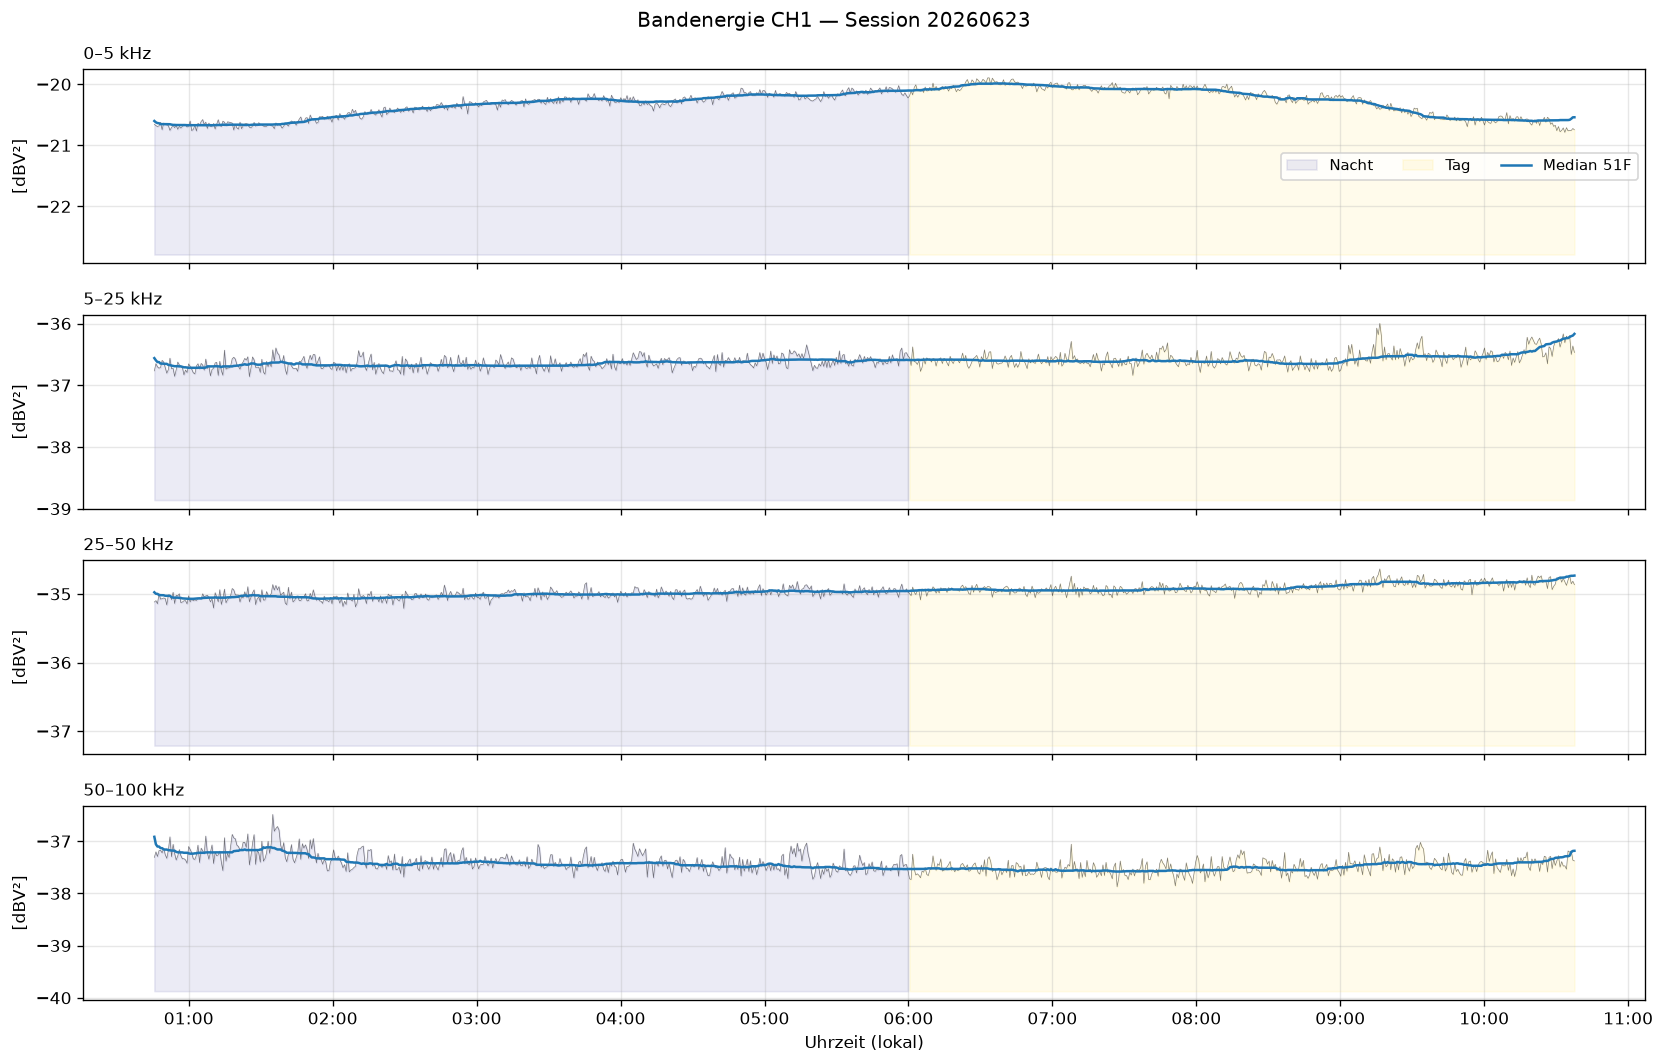

In [3]:
# band_energy: ordered list [ch1, ch3, ch4]; 20 bands x 5 kHz each (0–100 kHz)
BANDS = {
    "0–5 kHz":    (0,  1),
    "5–25 kHz":   (1,  5),
    "25–50 kHz":  (5, 10),
    "50–100 kHz": (10, 20),
}
CH_IDX = 0  # CH1 = Index 0

temps = [f.get("temperature_c") for f in frames]
has_temp = any(t is not None for t in temps)
n_rows = len(BANDS) + (1 if has_temp else 0)

fig, axes = plt.subplots(n_rows, 1, figsize=(14, 3 * n_rows), sharex=True)
band_axes = axes[:len(BANDS)]
temp_ax = axes[len(BANDS)] if has_temp else None

for ax, (label, (i0, i1)) in zip(band_axes, BANDS.items()):
    energy_db = np.array([
        10 * np.log10(max(sum(f["band_energy"][CH_IDX][i0:i1]), 1e-30))
        for f in frames
    ])
    ax.fill_between(ts_dt, energy_db, energy_db.min()-2,
                    where=night_mask, color="navy", alpha=0.08, label="Nacht")
    ax.fill_between(ts_dt, energy_db, energy_db.min()-2,
                    where=day_mask, color="gold", alpha=0.08, label="Tag")
    ax.plot(ts_dt, energy_db, "k-", lw=0.4, alpha=0.5)
    k = min(51, len(energy_db) // 2 * 2 - 1)
    if k >= 3:
        ax.plot(ts_dt, medfilt(energy_db, k), "tab:blue", lw=1.5, label="Median 51F")
    ax.set_ylabel("[dBV²]")
    ax.set_title(label, loc="left", fontsize=10)
    if label == list(BANDS.keys())[0]:
        ax.legend(fontsize=9, ncol=3)

if has_temp and temp_ax is not None:
    temp_vals = np.array([t if t is not None else float("nan") for t in temps])
    temp_ax.plot(ts_dt, temp_vals, color="tab:red", lw=1.2, label="Temperatur °C")
    temp_ax.set_ylabel("°C")
    temp_ax.set_title("Raumtemperatur (HA satellite1)", loc="left", fontsize=10)
    temp_ax.legend(fontsize=9)

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
axes[-1].set_xlabel("Uhrzeit (lokal)")
fig.suptitle(f"Bandenergie CH1 + Temperatur — Session {SESSION_ID[:8]}", fontsize=12)
fig.tight_layout()
plt.show()

### Persistent Cross-Channel Peaks: Top 10

Most frequent peaks (±200 Hz bin, present on ≥ 2 channels, ≥ 12 frames).
Circle = all 3 channels (common-mode); triangle = 2 channels.

Cross-channel persistence is a standard criterion for distinguishing
real structural signals from single-sensor artefacts (De Roo et al., 2016).


Persistente Peaks: 245 in 81 Frequenz-Buckets


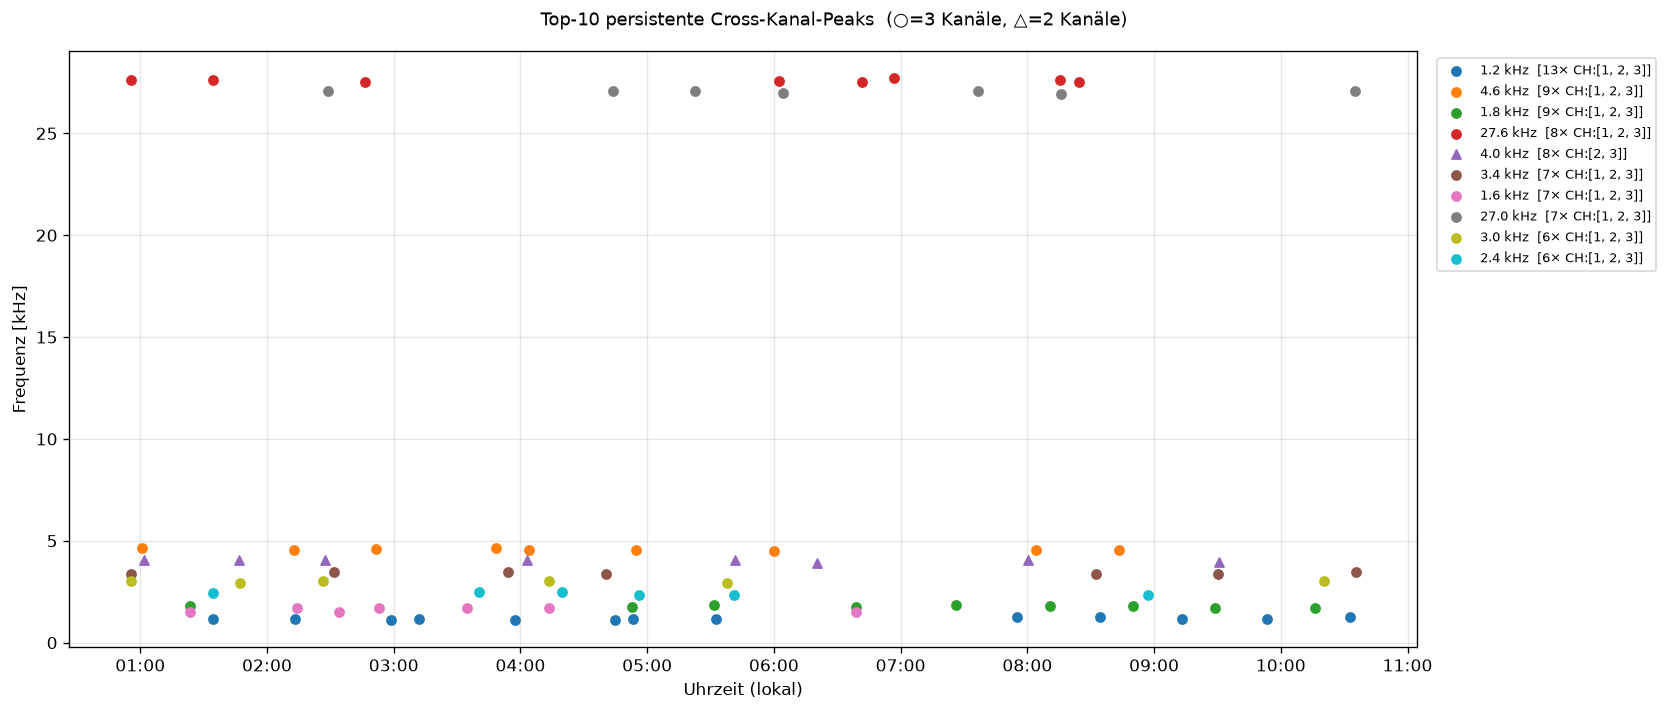

In [4]:
peak_events = by_type.get("persistent_cross_channel_peak", [])
buckets = defaultdict(list)
for e in peak_events:
    b = round(e["frequency_hz"] / 200) * 200
    buckets[b].append(e)

top10 = sorted(buckets.items(), key=lambda x: len(x[1]), reverse=True)[:10]
print(f"Persistent peaks: {len(peak_events)} in {len(buckets)} frequency buckets")

fig, ax = plt.subplots(figsize=(14, 6))
for (bucket, lst), color in zip(top10, plt.cm.tab10(np.linspace(0, 1, len(top10)))):
    ts_e  = [datetime.fromtimestamp(datetime.fromisoformat(e["timestamp_utc"]).timestamp()) for e in lst]
    freqs = [e["frequency_hz"] / 1e3 for e in lst]
    chs   = sorted(set(c for e in lst for c in e["channels"]))
    label = f"{bucket/1e3:.1f} kHz  [{len(lst)}× CH:{chs}]"
    marker = "o" if len(chs) == 3 else "^"
    ax.scatter(ts_e, freqs, color=color, s=30, marker=marker, label=label, zorder=3)

ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_xlabel("Uhrzeit (lokal)")
ax.set_ylabel("Frequenz [kHz]")
ax.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
fig.suptitle("Top-10 persistent cross-channel peaks  (○=3 channels, △=2 channels)", fontsize=11)
fig.tight_layout()
plt.show()

### Cross-Channel Frequency Drift

Trajectory of participating peaks ±80 frames around the event.
Frequency drift correlated with temperature may indicate thermal
resonance shift of sensor or substrate (Zweifel & Zeugin, 2008).


Drift-Ereignisse: 1
  Seq  514  81.26->81.76 kHz  +1.09 Hz/s  CH:[1, 2]  R²=0.87  [day]


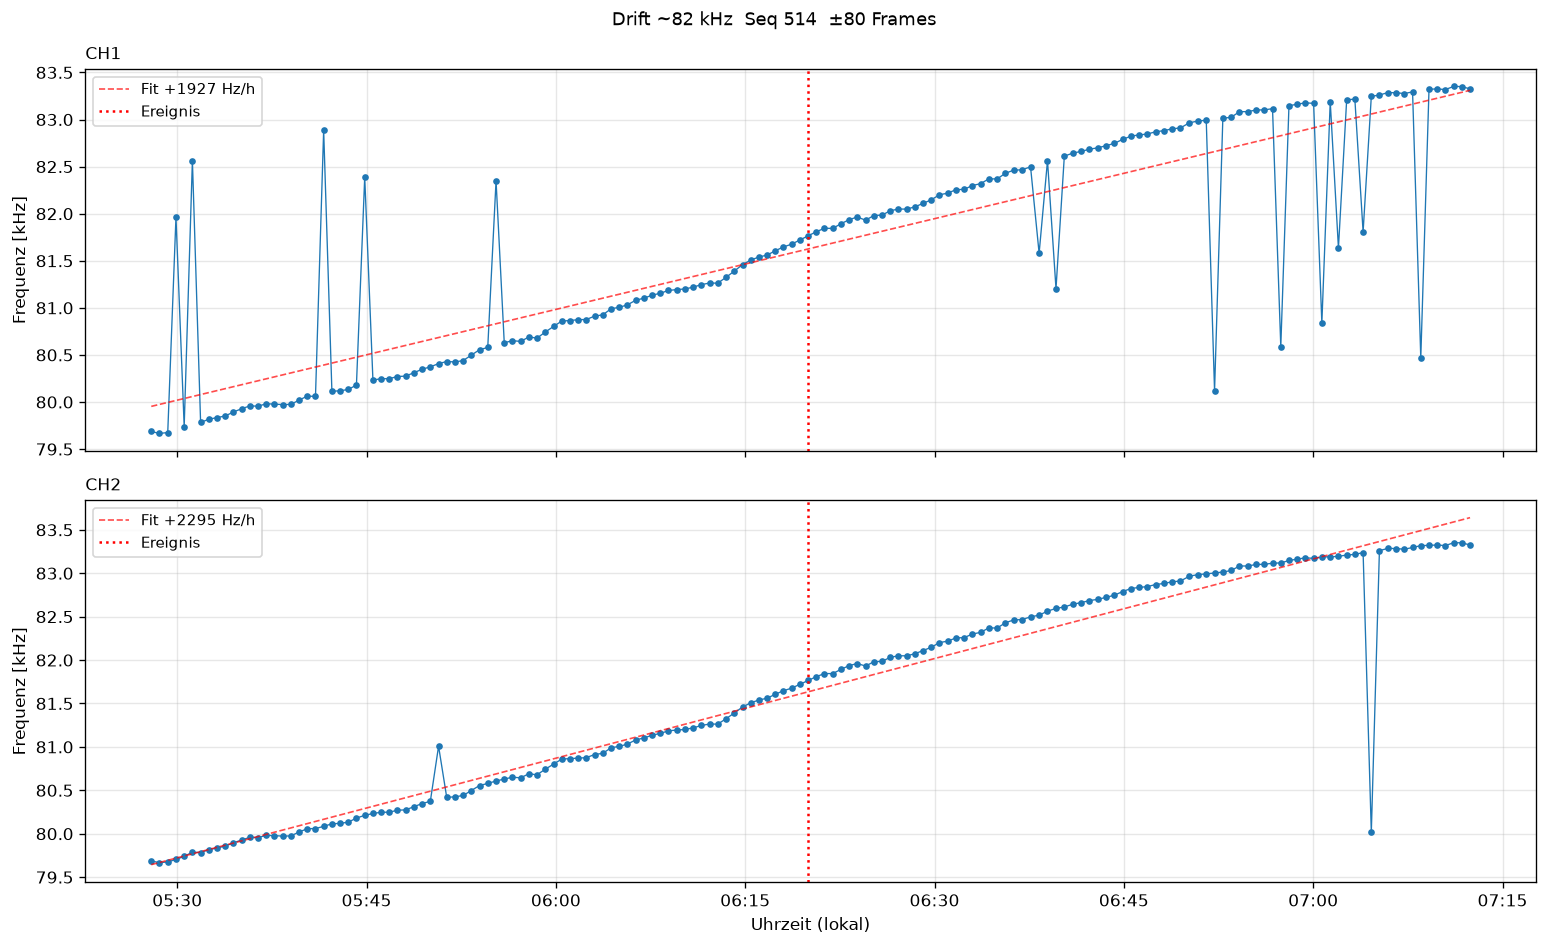

In [5]:
drift_events = by_type.get("cross_channel_frequency_drift", [])
print(f"Drift events: {len(drift_events)}")
for de in drift_events:
    print(f"  Seq {de['sequence']:4d}  "
          f"{de['start_frequency_hz']/1e3:.2f}->{de['end_frequency_hz']/1e3:.2f} kHz  "
          f"{de['slope_hz_per_second']:+.2f} Hz/s  CH:{de['channels']}  "
          f"R²={de['minimum_r_squared']:.2f}  [{de.get('light_phase','?')}]")

for de in drift_events:
    target = (de["start_frequency_hz"] + de["end_frequency_hz"]) / 2
    tol, window = 5000.0, 80
    seq_d = de["sequence"]
    chs = de["channels"]
    fig, axes = plt.subplots(len(chs), 1, figsize=(13, 4 * len(chs)), sharex=True)
    if len(chs) == 1:
        axes = [axes]
    for ax, ch in zip(axes, chs):
        traj_t, traj_f = [], []
        for f in frames:
            if abs(f["sequence"] - seq_d) > window:
                continue
            cands = [p for p in f["peaks"][str(ch)]
                     if abs(p["frequency_hz"] - target) < tol]
            if cands:
                best = min(cands, key=lambda p: abs(p["frequency_hz"] - target))
                traj_t.append(datetime.fromtimestamp(datetime.fromisoformat(f["timestamp_utc"]).timestamp()))
                traj_f.append(best["frequency_hz"] / 1e3)
        if traj_t:
            ax.plot(traj_t, traj_f, "o-", ms=3, lw=0.8, color="tab:blue")
            t_num = np.array([(t - traj_t[0]).total_seconds() for t in traj_t])
            coeffs = np.polyfit(t_num, np.array(traj_f) * 1e3, 1)
            t_fit  = np.linspace(0, t_num[-1], 200)
            ax.plot([datetime.fromtimestamp(traj_t[0].timestamp() + dt) for dt in t_fit],
                    np.polyval(coeffs, t_fit) / 1e3, "r--", lw=1, alpha=0.7,
                    label=f"Fit {coeffs[0]*3600:+.0f} Hz/h")
        ts_ev = datetime.fromtimestamp(datetime.fromisoformat(de["timestamp_utc"]).timestamp())
        ax.axvline(ts_ev, color="red", lw=1.5, linestyle=":", label="Ereignis")
        ax.set_ylabel("Frequenz [kHz]")
        ax.set_title(f"CH{ch}", loc="left", fontsize=10)
        ax.legend(fontsize=9)
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    axes[-1].set_xlabel("Uhrzeit (lokal)")
    fig.suptitle(f"Drift ~{target/1e3:.0f} kHz  Seq {seq_d}  ±{window} Frames", fontsize=11)
    fig.tight_layout()
    plt.show()

### Long-Term Trend Analysis

`summarize_monitor_sessions()` computes hourly medians and linear trend
across all stored sessions.


In [6]:
summary = summarize_monitor_sessions()
print(f"Sessions: {summary['sessions']}  Frames/Phase: {summary['phase_frames']}")

trends = summary.get("top_trends", [])
if trends:
    df = pd.DataFrame(trends[:15])[
        ["kind","channel","label","total_change","slope_per_hour",
         "r_squared","start_local","end_local","hourly_points"]
    ].rename(columns={
        "total_change": "Delta_total",
        "slope_per_hour": "Slope [/h]",
        "r_squared": "R²",
        "start_local": "Start",
        "end_local": "End",
        "hourly_points": "Hours",
    })
    display(df)
else:
    print("No trends yet (may require at least two sessions)")

Sessions: 1  Frames/Phase: {'night': 484, 'day': 423}


,kind,channel,label,Δ gesamt,Slope [/h],R²,Start,Ende,Stunden
0,peak_frequency,2,peak near 53 kHz,-394.543294,-49.566518,0.809714,2026-06-23T03:00:00+02:00,2026-06-23T10:00:00+02:00,7
1,peak_frequency,1,peak near 32.5 kHz,369.827699,29.107451,0.670122,2026-06-23T00:00:00+02:00,2026-06-23T10:00:00+02:00,11
2,peak_frequency,2,peak near 99 kHz,-398.983567,-66.410029,0.952103,2026-06-23T01:00:00+02:00,2026-06-23T07:00:00+02:00,4
3,peak_frequency,2,peak near 62.5 kHz,-411.412517,-44.897225,0.703153,2026-06-23T01:00:00+02:00,2026-06-23T09:00:00+02:00,7
4,peak_frequency,2,peak near 49.5 kHz,350.841035,44.683556,0.860356,2026-06-23T01:00:00+02:00,2026-06-23T09:00:00+02:00,5
5,peak_frequency,2,peak near 58.5 kHz,-387.659615,-43.669540,0.692480,2026-06-23T01:00:00+02:00,2026-06-23T09:00:00+02:00,6
6,peak_frequency,3,peak near 63.5 kHz,-348.053607,-24.187184,0.601062,2026-06-23T00:00:00+02:00,2026-06-23T10:00:00+02:00,11
7,peak_frequency,2,peak near 4.5 kHz,-299.542889,-35.245153,0.688064,2026-06-23T00:00:00+02:00,2026-06-23T10:00:00+02:00,11
8,peak_frequency,1,peak near 5.5 kHz,365.543701,52.568682,0.746853,2026-06-23T01:00:00+02:00,2026-06-23T09:00:00+02:00,5
9,peak_frequency,1,peak near 31.5 kHz,431.827184,30.334157,0.466444,2026-06-23T01:00:00+02:00,2026-06-23T10:00:00+02:00,10


### Differential Analysis: Plant Candidates vs. EM Reference

> **Legacy note (Phase 1 only):** This cell is only meaningful for historical sessions where
> CH3 was used as an external EM reference (sessions before 2026-06-23 CH2 defect).
> It is not valid for the active 2026-06-30 setup, where CH1/CH3/CH4 are all amplified piezo sensors
> and CH3/CH4 are metal-rod-coupled.

**Phase 1 logic:** CH1/CH2 = plant sensors; CH3 = EM reference.
Peaks on CH1 or CH2 absent from CH3 are plant signal candidates.
Peaks on CH3 indicate EM coupling (discard).


In [ ]:
# Differential analysis: plant channels (CH1/CH2) vs. EM reference (CH3)
# Only valid for Phase 1 sessions where CH3 was the external EM reference (before 2026-06-23 defect).
# Active 2026-06-30 setup: do not use this legacy Phase 1 analysis; CH1/CH3/CH4 are all amplified piezo sensors and CH3/CH4 are metal-rod-coupled.

from collections import Counter

REF_CHANNEL = "3"           # Phase 1: CH3 = EM reference
PLANT_CHANNELS = ["1", "2"] # Phase 1: CH1, CH2 = plant channels
BIN_HZ = 200                # frequency bin for comparison

def freq_bin(hz, b=BIN_HZ):
    return round(hz / b) * b

plant_only = Counter()  # peaks on CH1/CH2, NOT on CH3
em_only    = Counter()  # peaks on CH3, NOT on CH1/CH2
common     = Counter()  # peaks on both plant and reference

for f in frames:
    peaks = f.get("peaks", {})
    ch_plant = set()
    for ch in PLANT_CHANNELS:
        for p in peaks.get(ch, []):
            ch_plant.add(freq_bin(p["frequency_hz"]))
    ch_ref = {freq_bin(p["frequency_hz"]) for p in peaks.get(REF_CHANNEL, [])}

    for freq in ch_plant - ch_ref:
        plant_only[freq] += 1
    for freq in ch_ref - ch_plant:
        em_only[freq] += 1
    for freq in ch_plant & ch_ref:
        common[freq] += 1

N = len(frames)
print(f"Session: {SESSION_ID}  |  {N} Frames")
print()
print(f"{'Freq [kHz]':>10}  {'Frames':>6}  {'%':>5}  Interpretation")
print("-" * 55)
print("--- Pflanzenkandidaten (CH1/CH2 ohne CH3) ---")
for freq, cnt in plant_only.most_common(15):
    print(f"{freq/1000:>10.2f}  {cnt:>6}  {100*cnt/N:>4.0f}%")
print()
print("--- EM-Gleichtakt (auf CH3) ---")
for freq, cnt in em_only.most_common(10):
    print(f"{freq/1000:>10.2f}  {cnt:>6}  {100*cnt/N:>4.0f}%  [EM]")

# Visualisierung
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8))

freqs_p = sorted(plant_only.keys())
cnts_p  = [plant_only[f] for f in freqs_p]
ax1.bar([f/1000 for f in freqs_p], [100*c/N for c in cnts_p],
        width=BIN_HZ/1000*0.8, color="tab:green", alpha=0.8)
ax1.set_xlabel("Frequenz [kHz]")
ax1.set_ylabel("Frames [%]")
ax1.set_title("Pflanzenkandidaten (CH1 oder CH2, NICHT CH3)", fontsize=11)
ax1.set_xlim(0, 100)

freqs_e = sorted(em_only.keys())
cnts_e  = [em_only[f] for f in freqs_e]
ax2.bar([f/1000 for f in freqs_e], [100*c/N for c in cnts_e],
        width=BIN_HZ/1000*0.8, color="tab:red", alpha=0.8)
ax2.set_xlabel("Frequenz [kHz]")
ax2.set_ylabel("Frames [%]")
ax2.set_title("EM-Gleichtakt (auf CH3-Referenz)", fontsize=11)
ax2.set_xlim(0, 100)

fig.tight_layout()
plt.show()


### Scientific Context

#### Active Channel Setup (from 2026-06-30)

| Channel | Signal | Source / Position | Role |
|---------|--------|-------------------|------|
| CH1 | amplifier + 820 kΩ + piezo | piezo probe | acoustic sensor |
| CH2 | **DISABLED** | — | Hardware defect / spare only if explicitly re-enabled |
| CH3 | amplifier + 820 kΩ + piezo + metal rod | metal-rod probe A | acoustic sensor / rod-coupled response |
| CH4 | amplifier + **410 kΩ** + piezo + metal rod | metal-rod probe B | acoustic sensor / rod-coupled response (410kΩ from 2026-07-01) |

#### Confirmed Findings (as of 2026-06-27)

The findings below come from the earlier passive/plant-monitoring setup. Keep them separate
from the current 2026-06-30 hardware setup, where CH1/CH3/CH4 are all amplified piezo sensors.

**1. Diurnal coherence pattern at ~3800 Hz (Welch coherence CH3/CH4)**
  - Night (22:00–06:00): mean 0.80
  - Day (06:00–22:00): mean 0.27
  - Natural spread σ = 0.22
  - CH1/CH4 coherence at 3800 Hz: 0.002–0.04 (at or below bias floor 1/N_seg ≈ 0.056)
  - Reproduced across ≥ 3 independent nights (2026-06-22 to 2026-06-27)
  - Tracked frequency mean ~15–70 Hz above 5×750 Hz building harmonic (3750 Hz)

**2. 6747 Hz = structural artefact (9th harmonic of building HVAC pump, 9×750 Hz)**
  - CH3/CH4 coherence mean 0.124, no frame > 0.5
  - All frames carry `nearest_artifact_hz`, `artifact_offset_hz`, `coherence_bias_floor`

**3. Watering response at 3800 Hz**
  - First event (2026-06-23): CH3 +21.7 dB after 10 s watering
  - Narrowband (0–5 kHz total band energy +0.2 dB only) — not pump injection

**Coherence bias floor:** 1/N_segments = 1/18 ≈ 0.056 (Welch, nperseg=16384,
~18 segments at 300 000 points). Coherence values at or below this floor are not significant
(Carter, 1987).

---
*References (see also `../../../../Abgrenzung/abgrenzungstabelle_akustisch_pil.md` rows 31–36, 43):*
- Zweifel & Zeugin (2008) — `zweifel_ultrasonic_2008`
- De Roo et al. (2016) — `de_roo_acoustic_2016`
- Khait et al. (2023) — `khait_sounds_2023`
- Oletic et al. (2020) — `oletic_time_2020`
- Saha & Rastogi (2026) — `saha_plant_2026`
- Carter (1987) — coherence estimation bias: G.C. Carter, 'Coherence and time delay estimation', Proc. IEEE 75(2)


---
### Ultrasonic Band Analysis — CH4 410 kΩ (2026-07-01+)

Loads hourly PSD snapshots and computes day / night average spectra for all three
channels across the full 0–250 kHz range.  CH4 was modified to 410 kΩ on 2026-07-01;
sessions before that date use 820 kΩ on all channels.

Expected: CH4 shows elevated PSD above ~5 kHz relative to CH3 (validated by NB15).

In [ ]:
# ── Ultrasonic PSD snapshot analysis ─────────────────────────────────────────
from scipy.ndimage import uniform_filter1d

snap_dir = SESSION_DIR / 'psd_snapshots'
snap_files = sorted(snap_dir.glob('psd_snapshot_*.npz')) if snap_dir.exists() else []
print(f'PSD snapshots: {len(snap_files)}')

if snap_files:
    day_psds, night_psds = [], []
    freq_snap = None
    for sf in snap_files:
        # infer day/night from filename timestamp (UTC hour)
        ts_str = sf.stem.split('_seq')[0].replace('psd_snapshot_', '').replace('T', ' ').replace('-', ':')
        # filename pattern: psd_snapshot_2026-07-01T18-00-35_seq...
        hour_utc = int(sf.stem.split('T')[1].split('-')[0])
        d = np.load(sf)
        if freq_snap is None:
            freq_snap = d['frequencies'].astype(float)
        # phase: UTC 06-22 = CEST 08-00 = day; approximate
        phase = 'day' if 4 <= hour_utc < 20 else 'night'
        (day_psds if phase == 'day' else night_psds).append(d['mean_psd'])

    CH_COLORS_SNAP = {0: '#1f77b4', 1: '#2ca02c', 2: '#d62728'}
    CH_NAMES_SNAP  = {0: 'CH1 820kΩ', 1: 'CH3 820kΩ', 2: 'CH4 410kΩ'}

    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
    fig.suptitle(f'Ultrasonic PSD — Session {SESSION_ID}  ·  {len(snap_files)} snapshots', fontsize=10)

    for ax, (group, label) in zip(axes, [(day_psds, 'Day (04–20 UTC)'), (night_psds, 'Night (20–04 UTC)')]):
        if not group:
            ax.text(0.5, 0.5, f'No {label.lower()} snapshots', transform=ax.transAxes, ha='center')
            continue
        mean_psd = np.mean(np.stack(group), axis=0)   # (3, N_freq)
        mask = (freq_snap >= 1000) & (freq_snap <= 250_000)
        fk = freq_snap[mask] / 1e3
        for i in range(3):
            ax.plot(fk, 10*np.log10(np.maximum(uniform_filter1d(mean_psd[i][mask], 20), 1e-30)),
                    lw=0.9, color=CH_COLORS_SNAP[i], label=CH_NAMES_SNAP[i])
        ax.set_title(f'{label}  (n={len(group)})', fontsize=9)
        ax.set_ylabel('PSD (dB re V²/Hz)')
        ax.legend(fontsize=8); ax.grid(True, lw=0.3, alpha=0.5)

    axes[1].set_xlabel('Frequency (kHz)')
    plt.tight_layout()
    plt.show()
else:
    print('No PSD snapshots yet — run again after the first full hour.')


### CH4 Selectivity — Plant vs. Structural Signal Candidates

For each `persistent_cross_channel_peak` event, compute the CH4–CH3 prominence
differential:

$$\Delta_{\text{sel}} = P_{\text{CH4}} - P_{\text{CH3}}$$

- **$\Delta_{\text{sel}} \gg 0$**: signal is stronger on CH4 than on the structural
  reference rod (CH3) → **plant-AE candidate**
- **$\Delta_{\text{sel}} \approx 0$**: co-propagation via rod structure → **structural artefact**
- **$\Delta_{\text{sel}} \ll 0$**: stronger on CH3, not CH4 → rod-specific, unrelated to plant

CH4 has 1–3 dB better sensitivity above 5 kHz (NB15), so a bias of ~+1–2 dB is expected
even for structural signals.  Events with $\Delta_{\text{sel}} > 5\,\text{dB}$ are flagged.

In [ ]:
# ── CH4 Selectivity analysis ──────────────────────────────────────────────────
SELECTIVITY_THRESHOLD_DB = 5.0   # CH4-CH3 prominence difference flagged as plant candidate

peak_events_all = by_type.get('persistent_cross_channel_peak', [])

sel_data = []
for e in peak_events_all:
    p = e.get('prominence_db', {})
    p4 = p.get('4', p.get(4, None))
    p3 = p.get('3', p.get(3, None))
    if p4 is None or p3 is None:
        continue
    sel = float(p4) - float(p3)
    sel_data.append({
        'ts': datetime.fromisoformat(e['timestamp_utc']),
        'freq_hz': e['frequency_hz'],
        'sel_db': sel,
        'prom_ch4': float(p4),
        'prom_ch3': float(p3),
        'phase': e.get('light_phase', '?'),
        'candidate': sel > SELECTIVITY_THRESHOLD_DB,
    })

print(f'Peak events with CH3+CH4 data: {len(sel_data)}')
candidates = [s for s in sel_data if s['candidate']]
print(f'Plant-AE candidates (Δsel > {SELECTIVITY_THRESHOLD_DB} dB): {len(candidates)}')

if sel_data:
    fig, axes = plt.subplots(2, 1, figsize=(14, 8))
    fig.suptitle(f'CH4 Selectivity  ·  Session {SESSION_ID}', fontsize=10)

    ax = axes[0]
    ax.set_title('CH4 − CH3 prominence differential  (Δsel) per event', fontsize=9)
    freqs = [s['freq_hz']/1e3 for s in sel_data]
    sels  = [s['sel_db'] for s in sel_data]
    colors = ['#d62728' if s['candidate'] else '#aaaaaa' for s in sel_data]
    ax.scatter(freqs, sels, c=colors, s=8, alpha=0.7, zorder=3)
    ax.axhline(SELECTIVITY_THRESHOLD_DB, color='#d62728', lw=0.8, ls='--',
               label=f'Candidate threshold (+{SELECTIVITY_THRESHOLD_DB} dB)')
    ax.axhline(0, color='k', lw=0.5, ls=':')
    ax.set_xlabel('Frequency (kHz)'); ax.set_ylabel('Δsel (dB)')
    ax.legend(fontsize=8); ax.grid(True, lw=0.3, alpha=0.5)

    ax = axes[1]
    ax.set_title('Δsel over time  (red = candidate, grey = structural)', fontsize=9)
    ts_e  = [s['ts'] for s in sel_data]
    ax.scatter(ts_e, sels, c=colors, s=8, alpha=0.7, zorder=3)
    ax.axhline(SELECTIVITY_THRESHOLD_DB, color='#d62728', lw=0.8, ls='--')
    ax.axhline(0, color='k', lw=0.5, ls=':')
    ax.set_xlabel('Time'); ax.set_ylabel('Δsel (dB)')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    fig.autofmt_xdate()
    ax.grid(True, lw=0.3, alpha=0.5)

    plt.tight_layout()
    plt.show()

    if candidates:
        print('\nTop plant-AE candidates:')
        print(f'{"Time":20s}  {"Freq":>10s}  {"Δsel":>8s}  {"CH4 prom":>10s}  {"CH3 prom":>10s}  Phase')
        print('-' * 75)
        for s in sorted(candidates, key=lambda x: -x['sel_db']):
            print(f'{str(s["ts"])[:19]:20s}  {s["freq_hz"]/1e3:>9.2f}k  '
                  f'{s["sel_db"]:>+8.1f}  {s["prom_ch4"]:>10.1f}  {s["prom_ch3"]:>10.1f}  {s["phase"]}')
else:
    print('No events with both CH3 and CH4 prominence data yet.')
